SESSION 3 - Distribution Plots (Histplot, Kdeplot) Topics: sns.histplot() sns.kdeplot() Combining hist + KDE Demo: Sales distribution visualizationPending
Tasks
1.
Import Seaborn and use sns.histplot() to visualize the distribution of delivery times (in minutes) from a sample Swiggy order dataset with at least 30 values.
2.
Download or create a list of daily step counts (e.g., from a fitness app) for one month and plot the distribution using sns.kdeplot(), showing the probability density curve.
3.
Combine sns.histplot() and sns.kdeplot() to visualize the distribution of monthly spending amounts (in rupees) on Zomato orders, using the same dataset for both plots on a single figure.<br><br><em><strong>Hint:</strong> Use the same data and overlay the KDE curve on the histogram by calling both functions on the same axes.</em>
4.
Given a dataset of IPL match scores, use sns.histplot() to plot the run distribution. Change the number of bins and observe how the plot changes. Write 2-3 lines about what you notice.<br><br><em><strong>Hint:</strong> Try bins=5, bins=10, and bins=20.</em>


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='darkgrid')
rng = np.random.default_rng(42)

Cell 2: Task 1, histplot of Swiggy delivery times (60 values)

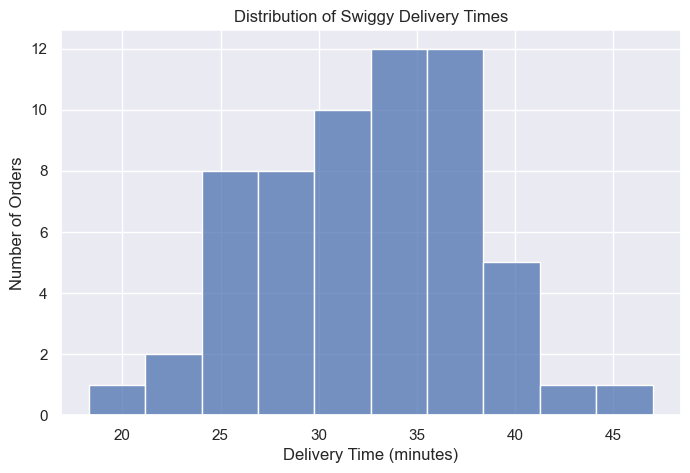

In [2]:
swiggy = pd.DataFrame({'delivery_time': rng.normal(32, 7, size=60).round(1).clip(10, 60)})

plt.figure(figsize=(8, 5))
sns.histplot(data=swiggy, x='delivery_time', bins=10)
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Number of Orders')
plt.title('Distribution of Swiggy Delivery Times')
plt.show()

Cell 3: Task 2, kdeplot of 30 days of steps

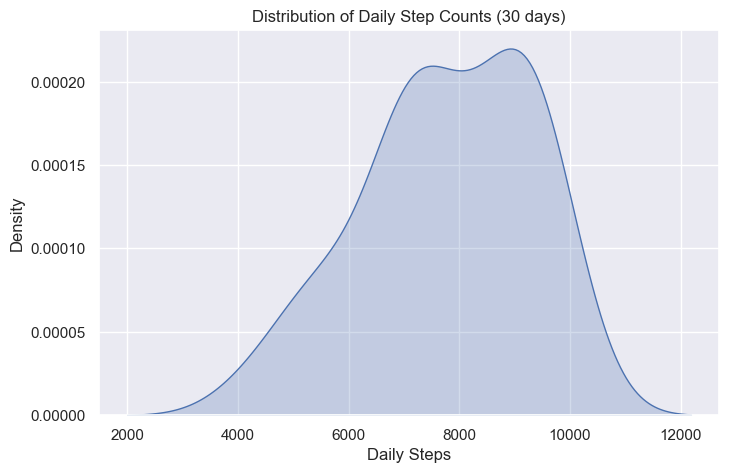

In [3]:
steps = rng.normal(8000, 2200, size=30).round().clip(2000, 15000).astype(int)
steps_df = pd.DataFrame({'day': range(1, 31), 'steps': steps})

plt.figure(figsize=(8, 5))
sns.kdeplot(data=steps_df, x='steps', fill=True)
plt.xlabel('Daily Steps')
plt.ylabel('Density')
plt.title('Distribution of Daily Step Counts (30 days)')
plt.show()

Cell 4: Task 3, histogram and KDE on the same axes

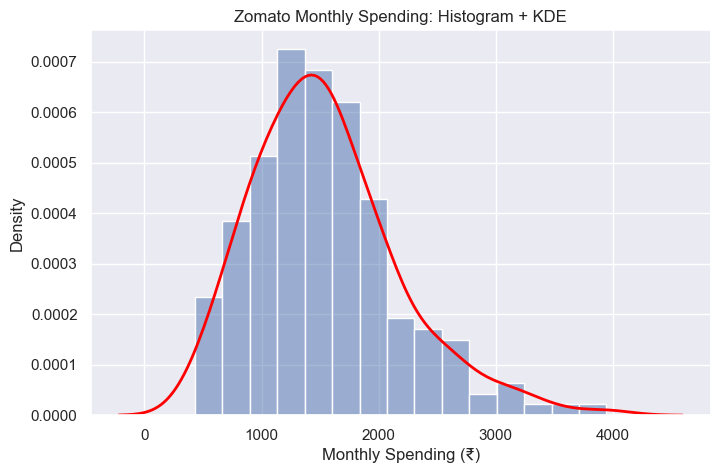

In [4]:
zomato = pd.DataFrame({'monthly_spend': rng.gamma(shape=6, scale=250, size=200).round(0)})

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=zomato, x='monthly_spend', bins=15, stat='density', alpha=0.5, ax=ax)
sns.kdeplot(data=zomato, x='monthly_spend', color='red', linewidth=2, ax=ax)
ax.set_xlabel('Monthly Spending (₹)')
ax.set_ylabel('Density')
ax.set_title('Zomato Monthly Spending: Histogram + KDE')
plt.show()

Cell 5: Task 4, IPL runs with different bins

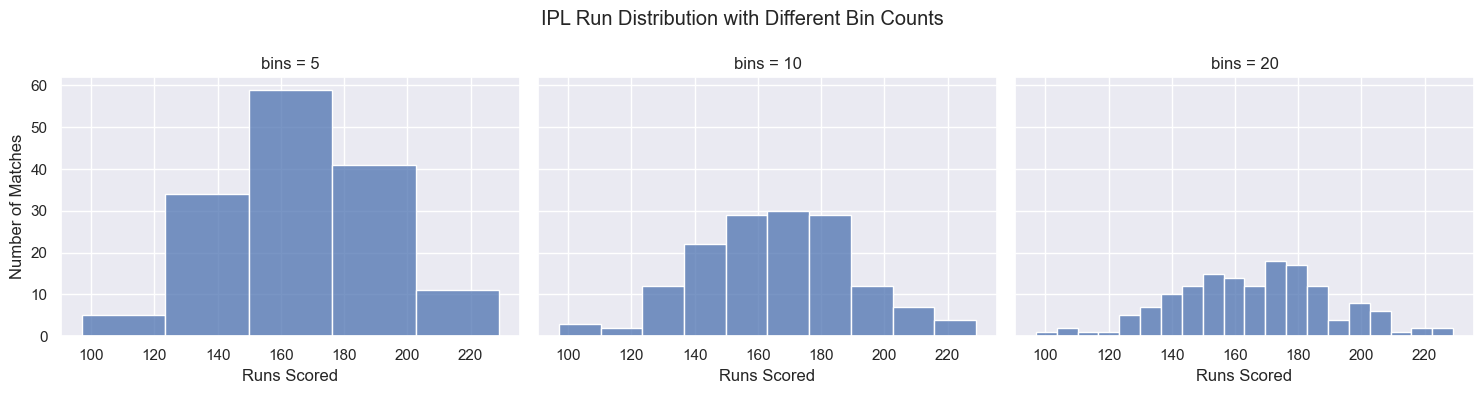

In [5]:
ipl = pd.DataFrame({'runs': rng.normal(168, 24, size=150).round().clip(90, 260).astype(int)})

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, b in zip(axes, [5, 10, 20]):
    sns.histplot(data=ipl, x='runs', bins=b, ax=ax)
    ax.set_title(f'bins = {b}')
    ax.set_xlabel('Runs Scored')
axes[0].set_ylabel('Number of Matches')
plt.suptitle('IPL Run Distribution with Different Bin Counts')
plt.tight_layout()
plt.show()